In [1]:
import mlflow
import mlflow.sklearn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay
)
import joblib

In [2]:
mlflow.end_run()

In [3]:
data = pd.read_csv(r"..\resources\archiv52e\heart_statlog_cleveland_hungary_final.csv")

In [4]:
data.columns

Index(['age', 'sex', 'chest pain type', 'resting bp s', 'cholesterol',
       'fasting blood sugar', 'resting ecg', 'max heart rate',
       'exercise angina', 'oldpeak', 'ST slope', 'target'],
      dtype='str')

In [5]:
X=data.drop(["target"],axis=1)
y=data["target"]


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42)

In [7]:
from sklearn.ensemble import RandomForestClassifier

In [8]:
pipeline_forest = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(random_state=42))
])
param_grid_forest = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 5, 10],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__criterion": ["gini", "entropy"]
}

In [9]:
grid_search_forest = GridSearchCV(
    estimator=pipeline_forest,
    param_grid=param_grid_forest,
    scoring="f1",
    return_train_score=True
)

Mejores parametros: {'classifier__criterion': 'entropy', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
test_accuracy: 0.9453781512605042
test_precision: 0.946969696969697
test_recall: 0.9541984732824428
test_f1_score: 0.9505703422053232
test_roc_auc: 0.9716415780837554
test_mse_classes: 0.0546218487394958
test_mse_probabilities_brier: 0.058674369747899156
test_mae_classes: 0.0546218487394958
test_mae_probabilities: 0.15903361344537817
test_r2_classes: 0.7792680316758223
test_r2_probabilities: 0.762891417564386


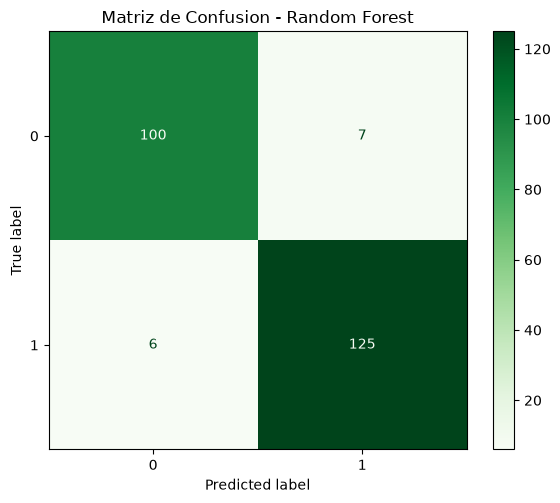

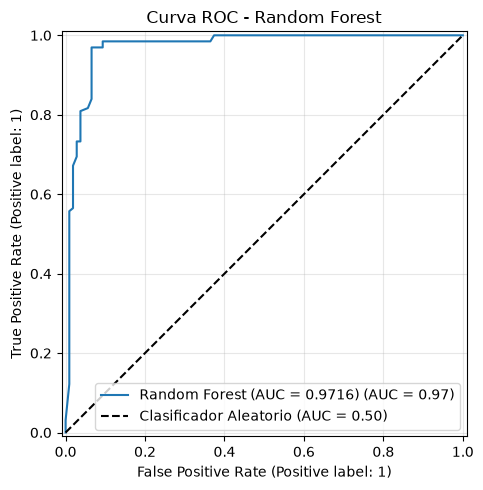

-> VALOR AUC (Random Forest): 0.9716


In [10]:
mlflow.set_experiment("Clasificacion Heart decesease Arbol") 
with mlflow.start_run(run_name="RandomForestClassifier") as run:
    grid_search_forest.fit(X_train, y_train)
    pipeline_forest_best = grid_search_forest.best_estimator_
    params = grid_search_forest.best_params_
    best = grid_search_forest.best_score_
    print("Mejores parametros:", params)
    mlflow.log_params({
        "best_n_estimators": params["classifier__n_estimators"],
        "best_max_dept": params["classifier__max_depth"],
        "best_min_samples_split": params["classifier__min_samples_split"],
        "best_min_samples_leafr": params["classifier__min_samples_leaf"],
        "best_classifier__criterion": params["classifier__criterion"],
        "cv_scoring_refit": "f1"
    })
    mlflow.log_metric("cv_best_f1_score", best)
    y_pred = pipeline_forest_best.predict(X_test)
    y_proba = pipeline_forest_best.predict_proba(X_test)[:, 1]
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba)
    mse_class = mean_squared_error(y_test, y_pred)
    mse_proba = mean_squared_error(y_test, y_proba)
    mae_class = mean_absolute_error(y_test, y_pred)
    mae_proba = mean_absolute_error(y_test, y_proba)
    r2_class = r2_score(y_test, y_pred)
    r2_proba = r2_score(y_test, y_proba)
    mlflow.log_metrics({
        "test_accuracy": acc,
        "test_precision": prec,
        "test_recall": rec,
        "test_f1_score": f1,
        "test_roc_auc": roc_auc,
        "test_mse_classes": mse_class,
        "test_mse_probabilities_brier": mse_proba,
        "test_mae_classes": mae_class,
        "test_mae_probabilities": mae_proba,
        "test_r2_classes": r2_class,
        "test_r2_probabilities": r2_proba
    })
    print(
    f"test_accuracy: {acc}\n"
    f"test_precision: {prec}\n"
    f"test_recall: {rec}\n"
    f"test_f1_score: {f1}\n"
    f"test_roc_auc: {roc_auc}\n"
    f"test_mse_classes: {mse_class}\n"
    f"test_mse_probabilities_brier: {mse_proba}\n"
    f"test_mae_classes: {mae_class}\n"
    f"test_mae_probabilities: {mae_proba}\n"
    f"test_r2_classes: {r2_class}\n"
    f"test_r2_probabilities: {r2_proba}"
    )

    # --- 1. Matriz de Confusion ---
    fig_cm, ax_cm = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        cmap=plt.cm.Greens,
        ax=ax_cm
    )
    ax_cm.set_title("Matriz de Confusion - Random Forest")
    plt.tight_layout()
    mlflow.log_figure(fig_cm, "confusion_matrix.png")
    plt.show()

    # --- 2. Curva ROC con valor AUC indicado ---
    fig_roc, ax_roc = plt.subplots(figsize=(6, 5))
    roc_display = RocCurveDisplay.from_predictions(
        y_test, y_proba,
        name=f"Random Forest (AUC = {roc_auc:.4f})",
        ax=ax_roc
    )
    ax_roc.plot([0, 1], [0, 1], "k--", label="Clasificador Aleatorio (AUC = 0.50)")
    ax_roc.set_title("Curva ROC - Random Forest")
    ax_roc.legend(loc="lower right")
    ax_roc.grid(True, alpha=0.3)
    plt.tight_layout()
    mlflow.log_figure(fig_roc, "roc_curve.png")
    plt.show()

    print("==================================================")
    print(f"-> VALOR AUC (Random Forest): {roc_auc:.4f}")
    print("==================================================")


In [11]:
joblib.dump(pipeline_forest_best, r"..\resources\pkl\modelo.pkl")

['..\\resources\\pkl\\modelo.pkl']